# Premiers pas avec le module transformers d'HuggingFace : tokenization et poids d'attention

Copiez ce notebook et ajoutez votre nom au nom de la copie

**A rendre par mail marie.candito@gmail.com, avant le XXX minuit, avec comme objet du mail : MIDS TP3**

**sous forme de lien colab avec droits d'édition**

(partager > tous les utilisateurs qui ont le lien)



## The Huggingface startup

- https://huggingface.co/
- franco-american
- core = open-source library for NLP models
  - in particular : the **transformers**  module : training / use of transformer-based pretrained models
  - integrates **hundreds of pretrained models**, provided by various teams, worldwide
- business model? cf. usual models for open-source softwares https://blog.timescale.com/blog/how-open-source-software-makes-money-time-series-database-f3e4be409467/
  - in this case, "inference API" https://huggingface.co/pricing, API for fast usage of pretrained models


## Huggingface course

A lot of courses in NLP-with-huggingface : https://huggingface.co/learn/nlp-course/chapter1/1


# Tokenization into subwords

In [29]:
import torch

# import (after potential installation) of the transformers module
try:
  from transformers import AutoModel, AutoTokenizer
except ImportError:
  !pip install transformers
  from transformers import AutoModel, AutoTokenizer




# Browsing the available models

Huggingface is a hub for a huge number of transformer-based models, either pre-trained models (generally to be used in additional training for downstream tasks) or already fine-tuned models.

Models in Huggingface are identified by a name. E.g. "bert-base-multilingual-cased".
Cf. the list of models https://huggingface.co/models?sort=downloads

Each model is tagged with several tags, among which is the main (pre)training task. In the models' page, you can filter by tag (left panel).

**TODO_0**: Study the list of tasks https://huggingface.co/tasks and find out which correspond to masked language modeling and to "plain" (or "causal", or unidirectional left-to-right) language modeling.

**Answer**: tasks "fill-mask" and "text generation".


## Loading a tokenizer


Each model is associated with a specific tokenizer, with a specific vocabulary, and a specific mapping from forms to ids.

In order to use the model on new inputs, the tokenization needs to be the same as the one used on the pre-training corpus.

Given a model name, the AutoTokenizer / AutoModel / AutoConfig classes can "guess" the exact python class for the corresponding tokenizer / model / config.

For instance the **'bert-base-multilingual-cased'** name corresponds to the BertModel, BertTokenizerFast and BertConfig classes.

In [30]:

tokenizer = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")
print(type(tokenizer))


<class 'transformers.models.bert.tokenization_bert.BertTokenizer'>


In [31]:
sent = "Aujourd'hui, j'essaie de comprendre les intringuants transformers."

# "encode" method: tokenization + conversion to token ids :
print("1:", tokenizer.encode(sent))
# readable form
print("2:", tokenizer.convert_ids_to_tokens(tokenizer.encode(sent)))
print()

# without special symbols:
print("3:", tokenizer.encode(sent, add_special_tokens=False))
print("4:", tokenizer.convert_ids_to_tokens(tokenizer.encode(sent, add_special_tokens=False)))
print()

# equivalent to:
print("5:", tokenizer.tokenize(sent))
print("6:", tokenizer.convert_tokens_to_ids(tokenizer.tokenize(sent)))
print()

1: [101, 69169, 112, 17287, 117, 178, 112, 61872, 10112, 10104, 73932, 10152, 26391, 13135, 41542, 10107, 99662, 10901, 119, 102]
2: ['[CLS]', 'Aujourd', "'", 'hui', ',', 'j', "'", 'essai', '##e', 'de', 'comprendre', 'les', 'int', '##ring', '##uant', '##s', 'transform', '##ers', '.', '[SEP]']

3: [69169, 112, 17287, 117, 178, 112, 61872, 10112, 10104, 73932, 10152, 26391, 13135, 41542, 10107, 99662, 10901, 119]
4: ['Aujourd', "'", 'hui', ',', 'j', "'", 'essai', '##e', 'de', 'comprendre', 'les', 'int', '##ring', '##uant', '##s', 'transform', '##ers', '.']

5: ['Aujourd', "'", 'hui', ',', 'j', "'", 'essai', '##e', 'de', 'comprendre', 'les', 'int', '##ring', '##uant', '##s', 'transform', '##ers', '.']
6: [69169, 112, 17287, 117, 178, 112, 61872, 10112, 10104, 73932, 10152, 26391, 13135, 41542, 10107, 99662, 10901, 119]



# TODO1: comparison of tokenizers

We use now the tokenizer of the French model **FlauBERT**, *flaubert_base_cased*, an encoder-only model, pre-trained on the **MLM** task only
  * cf.
    * list of available models : https://huggingface.co/transformers/pretrained_models.html)
    * and FlauBERT's doc in HuggingFace https://huggingface.co/transformers/model_doc/flaubert.html
    * cf. paper Le et al. 2020 https://aclanthology.org/2020.lrec-1.302/  French team

*   load the *flaubert_base_cased*'s tokenizer
*   compare its tokenization with multilingual BERT's one
*   how do you explain that certain inflected forms are not split into subwords
*   what are the integer ids of the "special tokens" ?



In [32]:
texts = ["eoari8 é§ êêçth et aux avec ceux-ci, sont-ils et est-t-elle?",
         "J'essaie de comprendre les transformers.",
         "Nous comprenions bien le cours.",
         "Le code comprend des erreurs.",
         "Il n'a pas bien compris le nouveau cours!"]

In [33]:
# multilingual bert's tokenization
for sent in texts:
    print(tokenizer.encode(sent, add_special_tokens=True))
    print(tokenizer.convert_ids_to_tokens(tokenizer.encode(sent, add_special_tokens=True)))
    print()



[101, 13934, 12476, 11396, 263, 204, 264, 15915, 13406, 11143, 10131, 10754, 10460, 20859, 118, 11322, 117, 10647, 118, 13178, 10131, 10176, 118, 188, 118, 11117, 136, 102]
['[CLS]', 'eo', '##ari', '##8', 'é', '§', 'ê', '##ê', '##ç', '##th', 'et', 'aux', 'avec', 'ceux', '-', 'ci', ',', 'sont', '-', 'ils', 'et', 'est', '-', 't', '-', 'elle', '?', '[SEP]']

[101, 147, 112, 61872, 10112, 10104, 73932, 10152, 99662, 10901, 119, 102]
['[CLS]', 'J', "'", 'essai', '##e', 'de', 'comprendre', 'les', 'transform', '##ers', '.', '[SEP]']

[101, 52208, 10212, 30619, 95494, 10107, 12028, 10141, 14211, 119, 102]
['[CLS]', 'Nous', 'com', '##pre', '##nion', '##s', 'bien', 'le', 'cours', '.', '[SEP]']

[101, 10281, 16964, 29316, 10139, 98344, 10107, 119, 102]
['[CLS]', 'Le', 'code', 'comprend', 'des', 'erreur', '##s', '.', '[SEP]']

[101, 10282, 182, 112, 169, 10801, 12028, 33497, 10141, 14285, 14211, 106, 102]
['[CLS]', 'Il', 'n', "'", 'a', 'pas', 'bien', 'compris', 'le', 'nouveau', 'cours', '!', '[SEP

In [34]:
# flaubert's tokenization uses as first step a tokenization into words by moses
try:
  import sacremoses
except ImportError:
  !pip install sacremoses
  import sacremoses



In [35]:
# chargement du tokenizer  de flaubert-base-cased :
tokenizer_flaubert = AutoTokenizer.from_pretrained("flaubert/flaubert_base_cased")
print(type(tokenizer_flaubert))

<class 'transformers.models.flaubert.tokenization_flaubert.FlaubertTokenizer'>


In [36]:
# flaubert tokenization
for sent in texts:
    print(tokenizer_flaubert.encode(sent, add_special_tokens=True))
    print(tokenizer_flaubert.convert_ids_to_tokens(tokenizer_flaubert.encode(sent, add_special_tokens=True)))
    print()

[0, 303, 487, 3241, 378, 218, 11592, 4821, 4821, 3394, 3051, 18, 57, 47, 3531, 14, 11306, 18, 11893, 4891, 87, 1]
['<s>', 'e', 'o', 'ari', '8</w>', 'é</w>', '§</w>', 'ê', 'ê', 'ç', 'th</w>', 'et</w>', 'aux</w>', 'avec</w>', 'ceux-ci</w>', ',</w>', 'sont-ils</w>', 'et</w>', 'est-', 't-elle</w>', '?</w>', '</s>']

[0, 158, 5213, 15, 965, 22, 14659, 896, 16, 1]
['<s>', "J'</w>", 'essaie</w>', 'de</w>', 'comprendre</w>', 'les</w>', 'transform', 'ers</w>', '.</w>', '</s>']

[0, 150, 42582, 6663, 83, 20, 210, 16, 1]
['<s>', 'Nous</w>', 'compren', 'ions</w>', 'bien</w>', 'le</w>', 'cours</w>', '.</w>', '</s>']

[0, 55, 1138, 976, 23, 3842, 16, 1]
['<s>', 'Le</w>', 'code</w>', 'comprend</w>', 'des</w>', 'erreurs</w>', '.</w>', '</s>']

[0, 59, 51, 34, 42, 83, 681, 20, 238, 210, 82, 1]
['<s>', 'Il</w>', "n'</w>", 'a</w>', 'pas</w>', 'bien</w>', 'compris</w>', 'le</w>', 'nouveau</w>', 'cours</w>', '!</w>', '</s>']



## Réponse au TODO1

Dans **mBERT**, lorsqu’un mot est découpé, les sous-mots suivants commencent par `##`, alors que dans **FlauBERT** la fin d’un mot est marquée par `</w>`. On observe aussi que **FlauBERT garde parfois des mots entiers ou des formes avec apostrophes et traits d’union** comme `J'</w>` ou `ceux-ci</w>`, tandis que **mBERT les découpe davantage**. Enfin, les deux tokenizers ajoutent des tokens spéciaux au début et à la fin : `[CLS]` et `[SEP]` pour mBERT, et `<s>` et `</s>` pour FlauBERT. Certaines formes fléchies ne sont pas découpées en sous-mots parce qu’elles existent déjà dans le vocabulaire appris par le tokenizer lors de l’entraînement ; dans ce cas, le modèle peut les représenter directement comme un seul token. Cela arrive plus souvent avec FlauBERT, car il est entraîné uniquement sur du français et contient donc davantage de formes françaises complètes dans son vocabulaire.
Concernant les tokens spéciaux, leurs identifiants entiers sont 101 pour [CLS] et 102 pour [SEP] dans mBERT, et 0 pour \<s> et 1 pour \</s> dans FlauBERT.

# TODO2: produce input tensor for a batch of documents

We want to apply a pre-trained language model on a batch of say 32 documents.

We need to tokenize them (each document into a sequence of token ids, plus special symbols) and produce a tensor to serve as input for the FlauBERT pretrained language model.

In order to produce an input tensor containing the token id sequences for each document, **all documents need to be of the same length**.


This is done by **truncating** (too long sequences) and/or **padding** (which means adding dummy tokens at the end of too short sentences).

All this can be done at once using the `__call__` method of a tokenizer.
`
 * study the `__call__` method inherited by the FlaubertTokenizer class https://huggingface.co/transformers/model_doc/flaubert.html#transformers.FlaubertTokenizer

 * use the relevant options to  **truncate** / **pad** all sequences in `text` to a total length of 10 tokens (including tokens for special symbols)

 * print and explain each item in the output dictionary

 * what is the id of the padding symbol?

 * how can we obtain the torch tensors instead of lists of integers?


In [37]:
# Tokenisation + troncature + padding en une seule étape
encodings = tokenizer_flaubert(
    texts,
    truncation=True,            # Tronque les séquences plus longues que max_length
    padding="max_length",       # Pad toutes les séquences à une longueur fixe
    max_length=10,              # Longueur totale = 10 tokens (tokens spéciaux inclus)
    return_tensors="pt"         # Retourne des tenseurs PyTorch (au lieu de listes Python)
)

# Affichage des clés du dictionnaire retourné
print("Clés du dictionnaire de sortie :", list(encodings.keys()), "\n")

# 1) input_ids : identifiants des tokens (avec <s>, </s>, et éventuellement <pad>)
input_ids = encodings["input_ids"]
print("1) input_ids")
print("   - shape :", tuple(input_ids.shape))
print("   - description : ids des tokens, pad/tronqués à longueur 10")
print("   - valeurs :\n", input_ids, "\n")

# 2) attention_mask : 1 = token réel, 0 = padding
attention_mask = encodings["attention_mask"]
print("2) attention_mask")
print("   - shape :", tuple(attention_mask.shape))
print("   - description : masque (1 = token réel, 0 = <pad>)")
print("   - valeurs :\n", attention_mask, "\n")

# token_type_ids : parfois absent selon le tokenizer / modèle
if "token_type_ids" in encodings:
    token_type_ids = encodings["token_type_ids"]
    print("3) token_type_ids")
    print("   - shape :", tuple(token_type_ids.shape))
    print("   - description : segments (souvent tout à 0 ici)")
    print("   - valeurs :\n", token_type_ids, "\n")

# ID du token de padding
pad_token_id = tokenizer_flaubert.pad_token_id
pad_token = tokenizer_flaubert.pad_token
print("ID du token de padding :")
print(f"   - pad_token = {pad_token!r}")
print(f"   - pad_token_id = {pad_token_id}\n")

# Vérification : on a bien des tenseurs PyTorch
print("Types des tenseurs :")
print("   - input_ids :", type(input_ids))
print("   - attention_mask :", type(attention_mask))

Clés du dictionnaire de sortie : ['input_ids', 'attention_mask'] 

1) input_ids
   - shape : (5, 10)
   - description : ids des tokens, pad/tronqués à longueur 10
   - valeurs :
 tensor([[    0,   303,   487,  3241,   378,   218, 11592,  4821,  4821,     1],
        [    0,   158,  5213,    15,   965,    22, 14659,   896,    16,     1],
        [    0,   150, 42582,  6663,    83,    20,   210,    16,     1,     2],
        [    0,    55,  1138,   976,    23,  3842,    16,     1,     2,     2],
        [    0,    59,    51,    34,    42,    83,   681,    20,   238,     1]]) 

2) attention_mask
   - shape : (5, 10)
   - description : masque (1 = token réel, 0 = <pad>)
   - valeurs :
 tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]) 

ID du token de padding :
   - pad_token = '<pad>'
   - pad_token_id = 2

Types des tenseurs :
   - input_i

# TODO3 : Forward propagation of an encoder-only PLM

You will now run the PLM on the sentences in `texts`, considered as an input batch of documents.

 * Use `AutoModel.from_pretrained` to load the pretrained FlauBERT model
 * encode the sentences using the tokenizer
 * and forward propagate
 * and produce a tensor for the contextual representation at the last layer of the model, for the \<s\> token of each sequence in the batch



**Tips**:

* Study the members of its class (FlaubertModel) https://huggingface.co/transformers/model_doc/flaubert.html#flaubertmodel

* **NB** : FlaubertModel indirectly inherits from the `nn.Module` class

* in pytorch, all such classes implement a `forward` method for forward propagation

* but it should not be called directly, but using,  the `__call__` method

* study the `__forward__` method here https://huggingface.co/docs/transformers/model_doc/flaubert#flaubertmodel

* call it (via `__call__`) using the `return_dict=True` option, in order to better understand its output

* study the shape of the output tensor(s)

* rem: the attention mask is useless here (see below: padded tokens don't receive attention)

In [38]:
# charger le modèle encodeur pré-entraîné FlauBERT
model = AutoModel.from_pretrained("flaubert/flaubert_base_cased")

# nous avons déjà tokenisé ci-dessus et stocké les encodages ; utiliser la forme tensorielle
tensor_encodings = encodings["input_ids"]              # shape = (batch, seq_len)

# propagation avant ; return_dict=True renvoie une sortie de type dictionnaire nommé
output = model(input_ids=tensor_encodings, return_dict=True)

# last_hidden_state : tenseur de taille (batch_size, seq_len, hidden_size)
print("output.last_hidden_state shape:", output.last_hidden_state.shape)

# représentation contextuelle pour le token <s> de chaque séquence
# <s> est le premier token, situé à la position 0 dans chaque séquence
s_contextual_vectors = output.last_hidden_state[:, 0, :]
print("shape of <s> contextual vectors:", s_contextual_vectors.shape)

# afficher les vecteurs réels pour le batch
print("<s> vectors tensor:\n", s_contextual_vectors)


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 488.51it/s, Materializing param=position_embeddings.weight] 
FlaubertModel LOAD REPORT from: flaubert/flaubert_base_cased
Key                  | Status     |  | 
---------------------+------------+--+-
pred_layer.proj.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


output.last_hidden_state shape: torch.Size([5, 10, 768])
shape of <s> contextual vectors: torch.Size([5, 768])
<s> vectors tensor:
 tensor([[-2.5945e+00,  4.3585e-01, -1.2133e-01,  ..., -3.1167e+00,
         -8.5202e-01,  2.9323e+00],
        [-4.9054e-01, -7.9338e-02,  1.2022e-01,  ..., -5.9667e-01,
          1.3901e+00,  1.8761e+00],
        [-4.5637e-01,  1.5039e-01, -5.8168e-01,  ..., -4.9589e-01,
          1.3167e+00,  1.8955e+00],
        [-8.1730e-02, -4.5923e-01, -5.2235e-02,  ..., -2.3838e-03,
          9.1420e-01,  1.3428e+00],
        [-2.1181e+00, -8.1037e-01,  2.0389e-01,  ..., -2.0136e+00,
         -2.8865e-01,  1.1774e+00]], grad_fn=<SelectBackward0>)


# TODO4: study of self-attention weights

Let us focus on the 4th sentence, which ends with 2 pad tokens.

* Print the self-attention weights
  * for the 4th token of sent4 ("comprend")
  * on the first attention head of the last layer
* Is attention paid to padded tokens ?

Tips : study of self-attention weights
* find out how to output the attention weights
* study their shape
* isolate the weights for first head of last layer
* to find out where the self-attention weights are for a given token (the "comprend" token), remember these sum to 1

In [39]:
# exécuter le modèle en retournant aussi les matrices d'attention
with torch.no_grad():
    outputs_att = model(input_ids=input_ids, attention_mask=attention_mask, output_attentions=True)

attns = outputs_att.attentions  # tuple : un tenseur par couche
print(f"num layers: {len(attns)}")
print(f"attn tensor shape (per layer): {attns[0].shape}  # (batch, heads, seq_len, seq_len)")

# sélectionner la 4e phrase du batch (index 3)
sample_idx = 3
# dernière couche, première tête d'attention
last_layer_attn = attns[-1]  # shape (batch, num_heads, seq_len, seq_len)
print(f"last_layer_attn shape: {last_layer_attn.shape}")
head0 = last_layer_attn[sample_idx, 0]  # (seq_len, seq_len)

# tokens pour cet exemple
tokens = tokenizer_flaubert.convert_ids_to_tokens(input_ids[sample_idx].tolist())
print('tokens:', tokens)

# trouver l'index du token contenant 'comprend' (correspondance par sous-chaîne)
target = 'comprend'
tok_idx = None
for idx, t in enumerate(tokens):
    if target in t:
        tok_idx = idx
        break

if tok_idx is None:
    print('Could not find token containing "comprend" in tokens')
else:
    print(f"Target token index: {tok_idx}, token: {tokens[tok_idx]}")

    # poids d'attention du token tok_idx vers tous les autres tokens
    weights = head0[tok_idx]

    # trouver les indices des tokens de padding pour cet exemple
    pad_indices = [i for i, vid in enumerate(input_ids[sample_idx].tolist()) if vid == pad_token_id]
    print('pad_indices:', pad_indices)

    # afficher les poids alignés avec les tokens (valeurs flottantes tronquées)
    for i, w in enumerate(weights.tolist()):
        print(i, tokens[i], f"{w:.6f}")

    # somme des poids d'attention sur les tokens de padding
    pad_weight = sum(weights[i].item() for i in pad_indices) if pad_indices else 0.0
    print(f"Sum of attention weight on pad tokens: {pad_weight:.6f}")

num layers: 12
attn tensor shape (per layer): torch.Size([5, 12, 10, 10])  # (batch, heads, seq_len, seq_len)
last_layer_attn shape: torch.Size([5, 12, 10, 10])
tokens: ['<s>', 'Le</w>', 'code</w>', 'comprend</w>', 'des</w>', 'erreurs</w>', '.</w>', '</s>', '<pad>', '<pad>']
Target token index: 3, token: comprend</w>
pad_indices: [8, 9]
0 <s> 0.000000
1 Le</w> 0.000000
2 code</w> 0.000000
3 comprend</w> 0.979340
4 des</w> 0.000164
5 erreurs</w> 0.000045
6 .</w> 0.010758
7 </s> 0.009693
8 <pad> 0.000000
9 <pad> 0.000000
Sum of attention weight on pad tokens: 0.000000


# TODO5: Plotting attention matrices

Attention matrices at several layers can be vizualized using  matplotlib's `matshow` method

(which displays a color-coded matrix)

cf. https://matplotlib.org/stable/gallery/images_contours_and_fields/matshow.html#matshow

E.g. the attention matrix of the first head, at the 1st layer, or the last layer...


/tmp/ipykernel_20583/3632232024.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


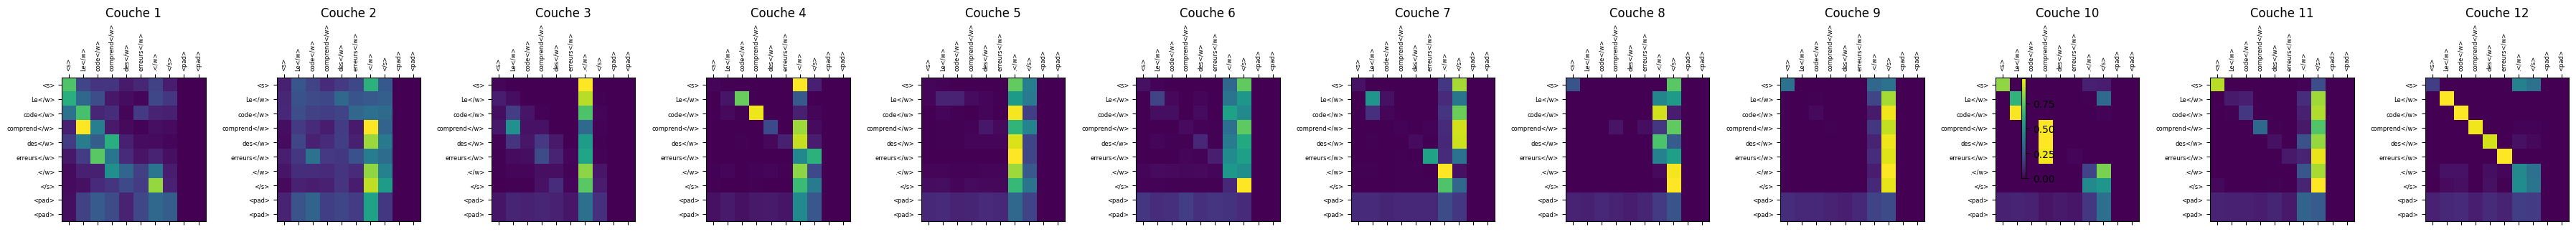

In [40]:
# plot of the attention weights for sent4, first attention head of each layer

import numpy as np
import matplotlib.pyplot as plt

# indice de la 4e phrase dans le batch
sample_idx = 3  # on commence à 0
# on récupère l'identifiant du token de padding pour éventuellement le repérer
pad_token_id = tokenizer_flaubert.pad_token_id

# la variable `attns` a été calculée précédemment : tuple de tenseurs
# un tenseur par couche de la forme (batch, num_heads, seq_len, seq_len)
num_layers = len(attns)

# création d'une figure avec une sous-figure par couche
fig, axes = plt.subplots(1, num_layers, figsize=(3*num_layers, 3))

# récupération des tokens (chaînes) pour la 4e phrase
tokens = tokenizer_flaubert.convert_ids_to_tokens(input_ids[sample_idx].tolist())

for layer in range(num_layers):
    # on isole la matrice d'attention de la 1re tête de cette couche
    layer_attn = attns[layer]  # shape (batch, heads, seq_len, seq_len)
    head0 = layer_attn[sample_idx, 0].detach().cpu().numpy()  # shape (seq_len, seq_len)

    ax = axes[layer] if num_layers > 1 else axes
    im = ax.matshow(head0, cmap='viridis')  # représentation colorée

    # ajouter un titre et les étiquettes de tokens sur les axes
    ax.set_title(f"Couche {layer+1}")
    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90, fontsize=6)
    ax.set_yticklabels(tokens, fontsize=6)

# barre de couleur commune pour toutes les sous-figures
fig.colorbar(im, ax=axes.flatten().tolist(), shrink=0.6)
plt.tight_layout()
plt.show()
